In [ ]:
import numpy as np
import tensorflow as tf
import pandas as pd  # For data handling
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
! pip install sent2vec
from keras.utils import to_categorical

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Load the data and create 2 lists with the headlines and the true sentiment.

In [ ]:
news_df = pd.read_csv('/content/drive/MyDrive/HLT project/Project files/sentiment_annotated_with_texts.csv')


In [ ]:
x = []
y = []

for t in news_df['title']:
    x.append(t)

for s in news_df['true_sentiment']:
    y.append(s)


Use the sent2vec Vectorizer on the titles and remove the stopwords {the, and, to, in}

In [ ]:
from sent2vec.vectorizer import Vectorizer
vectorizer = Vectorizer()
vectorizer.run(x, remove_stop_words=['the','and','to','in'])
vectors = vectorizer.vectors


Initializing Bert distilbert-base-uncased
Vectorization done on cpu


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:88: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.


In [ ]:
y = np.array(y)
x = np.array(vectors)


Then split the data into train and test set and create the MLPClassifier with 1 hidden layer with 80 neurons and using the adam solver. After this, train the model and evaluate the model printing

              precision    recall  f1-score   support

    Negative       0.57      0.61      0.59       142
     Neutral       0.60      0.55      0.58       163
    Positive       0.59      0.61      0.60       154

    accuracy                           0.59       459
   macro avg       0.59      0.59      0.59       459
weighted avg       0.59      0.59      0.59       459

['Negative' 'Neutral' 'Positive']
Model's accuracy on training set is 100.00%


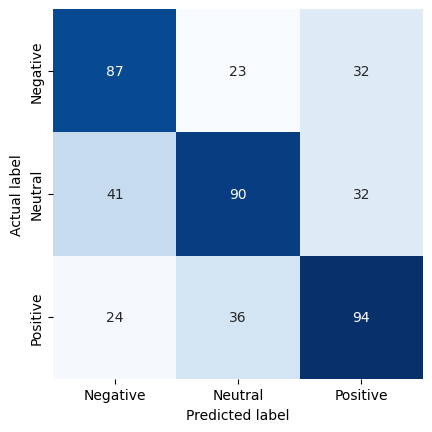

In [ ]:


x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 0,
    stratify=y,
    shuffle=True
)

model = MLPClassifier(
        random_state = 0,
        hidden_layer_sizes = (80,),
        activation = "relu",
        learning_rate = "invscaling",
        solver = "adam",
        max_iter = 900,
        tol= 1e-4,
        epsilon = 1e-3,
        alpha=0.00000001,
        shuffle=True,
        n_iter_no_change = 11,
        beta_2=0.99
)
model.fit(x_train, y_train)
y_predicted = model.predict(x_test)
print(classification_report(y_test, y_predicted))
print(model.classes_)
print(f'Model\'s accuracy on training set is {100 * model.score(x_train, y_train):.2f}%')
mat = confusion_matrix(y_test, y_predicted)

sns.heatmap(mat, square = True, annot = True, fmt = 'd', cbar = False, cmap = 'Blues',
    xticklabels = ['Negative', 'Neutral', 'Positive'],
    yticklabels = ['Negative', 'Neutral', 'Positive'])

plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.show()

In [ ]:
!pip freeze > '/content/drive/MyDrive/HLT project/requirements_MLP.txt'